In [4]:
import time
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az

In [6]:
# Load in dataset
df = pd.read_csv('../data/input/k_data.csv')

# Change all "ATH" to be "OAK" since the A's changed their name
df['Team'] = df['Team'].replace('ATH','OAK')

# Encode categorical data (PlayerId and Team)
id_factor, id_uniques = pd.factorize(df['PlayerId'])
df['PlayerId'] = id_factor
team_factor, team_uniques = pd.factorize(df['Team'])
df['Team'] = team_factor

# Standardize Stuff+ and Age
df['Stuff+'] = StandardScaler().fit_transform(pd.DataFrame(df['Stuff+']))
df['Age'] = StandardScaler().fit_transform(pd.DataFrame(df['Age']))

# Create training and testing datasets
input_cols = ['PlayerId', 'Team', 'TBF', 'Stuff+', 'Age']
output_cols = ['K%']
x_train = df.loc[df['Season']<2025,input_cols]
y_train = df.loc[df['Season']<2025,output_cols]
x_test = df.loc[df['Season']==2025,input_cols]
y_test = df.loc[df['Season']==2025,output_cols]

# Set input and output parameters
rng: np.random.Generator = np.random.default_rng(seed=26)
id = np.array(x_train['PlayerId'])
team = np.array(x_train['Team'])
tbf = np.array(x_train['TBF'])
stuff = np.array(x_train['Stuff+'])
age = np.array(x_train['Age'])
# Get number of strikeouts as opposed to strikeout percentage
y = [int(round(x)) for x in np.array(y_train).reshape(-1) * tbf]

# Make model
with pm.Model() as model:
    # Calculate the effect a given player or team has on K's 
    sigmaId = pm.HalfNormal('sigmaId', 1.0)
    sigmaTeam = pm.HalfNormal('sigmaTeam', 1.0)
    offsetId = pm.Normal('offsetId', mu=0, sigma=1, shape=len(np.unique(id)))
    offsetTeam = pm.Normal('offsetTeam', mu=0, sigma=1, shape=len(np.unique(team)))

    # Priors: Initially assume distribution for variables
    beta0 = pm.Normal('beta0', mu=0, sigma=1)
    betaStuff = pm.Normal('betaStuff', mu=0, sigma=1)
    betaAge = pm.Normal('betaAge', mu=0, sigma=1) 
    alphaId = offsetId * sigmaId
    alphaTeam = offsetTeam * sigmaTeam
  
    # Expected value of outcome
    log_odds = beta0 + betaStuff*stuff + betaAge*age + alphaId[id] + alphaTeam[team]
    
    # Likelihood (sampling distribution) of observations
    p = pm.math.sigmoid(log_odds)
    y_obs = pm.Binomial('y_obs', n=tbf, p=p, observed=y)

    # Draw 2,000 posterior samples
    trace = pm.sample(tune=1_500, draws=2_000, chains=4, cores=2, target_accept=0.9, progressbar=True, random_seed=rng)


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigmaId, sigmaTeam, offsetId, offsetTeam, beta0, betaStuff, betaAge]


c:\Users\cjmor\anaconda3\envs\newenv1\Lib\site-packages\rich\live.py:260: UserWarning: install "ipywidgets" for 
Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_500 tune and 2_000 draw iterations (6_000 + 8_000 draws total) took 210 seconds.


Time: 178.69591665267944


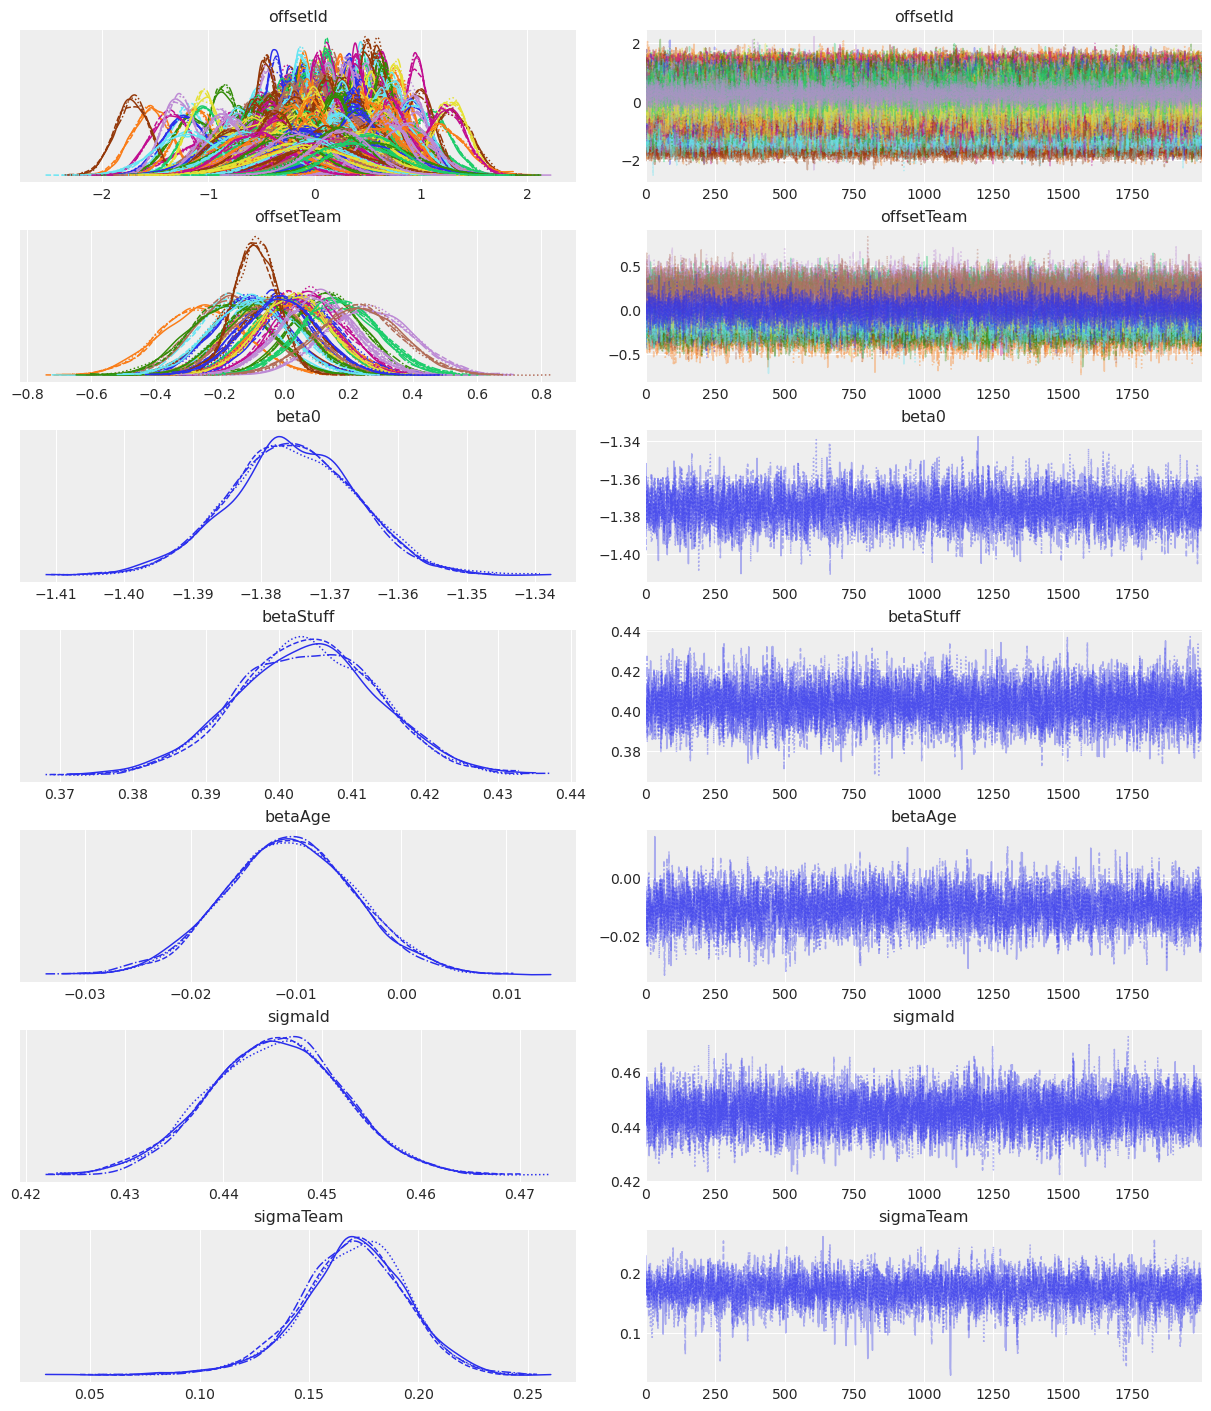

In [4]:
# Plot traces
start = time.time()
az.style.use('arviz-darkgrid')
az.plot_trace(trace);
print(f'Time: {time.time()-start}')

In [7]:
# Draw samples from distributions and calculate K% for each player in testing dataset
start = time.time()
estimates = []
# Create maps for categorical data
id_map = {value: code for code, value in enumerate(id_uniques)}
team_map = {value: code for code, value in enumerate(team_uniques)}

# Get estimate for each player in 2025 data
for i in range(len(x_test)):
    guess = []
    # Draw 100 samples
    for j in range(100):
        row = x_test.iloc[i,:]

        # Draw from distributions we just made
        b0_post = trace.posterior['beta0'].values.flatten()
        b0 = b0_post[np.random.randint(len(b0_post))]
        bs_post = trace.posterior['betaStuff'].values.flatten()
        bs= bs_post[np.random.randint(len(bs_post))]
        ba_post = trace.posterior['betaAge'].values.flatten()
        ba = ba_post[np.random.randint(len(ba_post))]

        # Get Stuff+ and Age values (already scaled), PlayerId and Team values, and TBF
        stuff_new = row['Stuff+']
        age_new = row['Age']
        id_new = int(row['PlayerId'])
        team_new = int(row['Team'])
        tbf_new = row['TBF']

        # Draw from the Player offset distribution corresponding to the given player
        try:
            offsetId_post = trace.posterior.offsetId[:,:,id_new].values.flatten()
            offset_id = offsetId_post[np.random.randint(len(offsetId_post))]
            sigmaId_post = trace.posterior['sigmaId'].values.flatten()
            sigma_id = sigmaId_post[np.random.randint(len(sigmaId_post))]
            alphaId_new = offset_id * sigma_id
        except:
            # If this player was not in the training data, set their player effect to 0
            alphaId_new = 0

        # Draw from the Team offset distribution corresponding to the given team
        offsetTeam_post = trace.posterior.offsetTeam[:,:,team_new].values.flatten()
        offset_team = offsetTeam_post[np.random.randint(len(offsetTeam_post))]
        sigmaTeam_post = trace.posterior['sigmaTeam'].values.flatten()
        sigma_team = sigmaTeam_post[np.random.randint(len(sigmaTeam_post))]
        alphaTeam_new = offset_team * sigma_team

        # Solve for logit(p) value
        logit_p = b0 + bs*stuff_new + ba*age_new + alphaId_new + alphaTeam_new

        # Inverse logit(p) to get the value of p
        p = 1 / (1 + np.exp(-logit_p))

        # Find an estimate for number of K
        k = np.random.binomial(n=tbf_new, p=p)

        # Calculate K% from k and tbf
        k_percent = k/tbf_new

        guess.append(k_percent)

    estimates.append(np.mean(guess))

print(f'Time: {time.time()-start}')
    

Time: 189.08530354499817


In [8]:
y_test['Estimate'] = estimates
y_test.to_csv('../data/output/solution.csv', index=False)
y_test

,K%,Estimate
3498,0.000000,0.020000
3499,0.000000,0.045000
3500,0.000000,0.020000
3501,0.000000,0.035185
3502,0.000000,0.050000
...,...,...
4366,0.278746,0.305331
4367,0.250000,0.343532
4368,0.160535,0.192241
4369,0.312500,0.354115


In [ ]:
# Find error
rmse = root_mean_squared_error(y_test.iloc[:,0], y_test.iloc[:,1])
print(rmse)

0.05906242296110786


### Without suspected position players

In [ ]:
# Load in dataset
df = pd.read_csv('k_2026.csv')

# Estimate position players see around 12 batters in a season. Filter players who saw less than 13 TBF.
df = df.loc[df['TBF']>12,:]

# Change all "ATH" to be "OAK" since the A's changed their name
df['Team'] = df['Team'].replace('ATH','OAK')

# Encode categorical data (PlayerId and Team)
id_factor, id_uniques = pd.factorize(df['PlayerId'])
df['PlayerId'] = id_factor
team_factor, team_uniques = pd.factorize(df['Team'])
df['Team'] = team_factor

# Standardize Stuff+ and Age
df['Stuff+'] = StandardScaler().fit_transform(pd.DataFrame(df['Stuff+']))
df['Age'] = StandardScaler().fit_transform(pd.DataFrame(df['Age']))

# Create training and testing datasets
input_cols = ['PlayerId', 'Team', 'TBF', 'Stuff+', 'Age']
output_cols = ['K%']
x_train = df.loc[df['Season']<2025,input_cols]
y_train = df.loc[df['Season']<2025,output_cols]
x_test = df.loc[df['Season']==2025,input_cols]
y_test = df.loc[df['Season']==2025,output_cols]

# Set input and output parameters
rng: np.random.Generator = np.random.default_rng(seed=26)
id = np.array(x_train['PlayerId'])
team = np.array(x_train['Team'])
tbf = np.array(x_train['TBF'])
stuff = np.array(x_train['Stuff+'])
age = np.array(x_train['Age'])
# Get number of strikeouts as opposed to strikeout percentage
y = [int(round(x)) for x in np.array(y_train).reshape(-1) * tbf]


# Make model
with pm.Model() as model:
    # Calculate the effect a given player or team has on K's 
    sigmaId = pm.HalfNormal('sigmaId', 1.0)
    sigmaTeam = pm.HalfNormal('sigmaTeam', 1.0)
    offsetId = pm.Normal('offsetId', mu=0, sigma=sigmaId, shape=len(np.unique(id)))
    offsetTeam = pm.Normal('offsetTeam', mu=0, sigma=sigmaTeam, shape=len(np.unique(team)))

    # Priors: Initially assume distribution for variables
    beta0 = pm.Normal('beta0', mu=0, sigma=1)
    betaStuff = pm.Normal('betaStuff', mu=0, sigma=1)
    betaAge = pm.Normal('betaAge', mu=0, sigma=1) 
    alphaId = offsetId * sigmaId
    alphaTeam = offsetTeam * sigmaTeam
  
    # Expected value of outcome. 
    log_odds = beta0 + betaStuff*stuff + betaAge*age + alphaId[id] + alphaTeam[team]
    
    # Likelihood (sampling distribution) of observations
    p = pm.math.sigmoid(log_odds)
    y_obs = pm.Binomial('y_obs', n=tbf, p=p, observed=y)

    # Draw 2,000 posterior samples
    trace = pm.sample(tune=1_500, draws=2_000, chains=4, cores=2, target_accept=0.9, progressbar=True, random_seed=rng)


c:\Users\cjmor\anaconda3\envs\pymc_env\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigmaId, sigmaTeam, offsetId, offsetTeam, beta0, betaStuff, betaAge]


Output()

Sampling 4 chains for 1_500 tune and 2_000 draw iterations (6_000 + 8_000 draws total) took 113 seconds.


In [ ]:
# Draw samples from distributions and calculate K% for each player in testing dataset
start = time.time()
estimates = []
# Create maps for categorical data
id_map = {value: code for code, value in enumerate(id_uniques)}
team_map = {value: code for code, value in enumerate(team_uniques)}

# Get estimate for each player in 2025 data
for i in range(len(x_test)):
    guess = []
    # Draw 100 samples
    for j in range(100):
        row = x_test.iloc[i,:]

        # Draw from distributions we just made
        b0_post = trace.posterior['beta0'].values.flatten()
        b0 = b0_post[np.random.randint(len(b0_post))]
        bs_post = trace.posterior['betaStuff'].values.flatten()
        bs= bs_post[np.random.randint(len(bs_post))]
        ba_post = trace.posterior['betaAge'].values.flatten()
        ba = ba_post[np.random.randint(len(ba_post))]

        # Get Stuff+ and Age values (already scaled), PlayerId and Team values, and TBF
        stuff_new = row['Stuff+']
        age_new = row['Age']
        id_new = int(row['PlayerId'])
        team_new = int(row['Team'])
        tbf_new = row['TBF']

        # Draw from the Player offset distribution corresponding to the given player
        try:
            offsetId_post = trace.posterior.offsetId[:,:,id_new].values.flatten()
            offset_id = offsetId_post[np.random.randint(len(offsetId_post))]
            sigmaId_post = trace.posterior['sigmaId'].values.flatten()
            sigma_id = sigmaId_post[np.random.randint(len(sigmaId_post))]
            alphaId_new = offset_id * sigma_id
        except:
            # If this player was not in the training data, set their player effect to 0
            alphaId_new = 0

        # Draw from the Team offset distribution corresponding to the given team
        offsetTeam_post = trace.posterior.offsetTeam[:,:,team_new].values.flatten()
        offset_team = offsetTeam_post[np.random.randint(len(offsetTeam_post))]
        sigmaTeam_post = trace.posterior['sigmaTeam'].values.flatten()
        sigma_team = sigmaTeam_post[np.random.randint(len(sigmaTeam_post))]
        alphaTeam_new = offset_team * sigma_team

        # Solve for logit(p) value
        logit_p = b0 + bs*stuff_new + ba*age_new + alphaId_new + alphaTeam_new

        # Inverse logit(p) to get the value of p
        p = 1 / (1 + np.exp(-logit_p))

        # Find an estimate for number of K
        k = np.random.binomial(n=tbf_new, p=p)

        # Calculate K% from k and tbf
        k_percent = k/tbf_new

        guess.append(k_percent)

    estimates.append(np.mean(guess))

print(f'Time: {time.time()-start}')
    

Time: 40.215699672698975


In [ ]:
# Add estimates to DataFrame containing observed values
y_test['Estimate'] = estimates

# Find error
rmse = root_mean_squared_error(y_test.iloc[:,0], y_test.iloc[:,1])
print(rmse)
y_test

0.05184587820925814


,K%,Estimate
3501,0.000000,0.037778
3504,0.066667,0.043333
3511,0.000000,0.058125
3514,0.000000,0.059286
3517,0.000000,0.053684
...,...,...
4366,0.278746,0.297805
4367,0.250000,0.352302
4368,0.160535,0.188829
4369,0.312500,0.349427


### Plot of K% and TBF

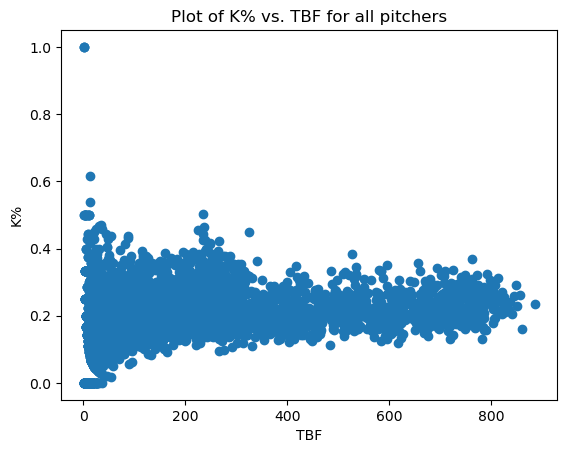

In [6]:
# Plot K% vs TBF
plt.scatter(df['TBF'],df['K%'])
plt.xlabel('TBF')
plt.ylabel('K%')
plt.title('Plot of K% vs. TBF for all pitchers')
plt.show()